# Gaia epoch photometry as an orbital clock: ATLAS J1013−4516

Self-contained figure notebook for the MIT Gaia DR4 Warm Up Workshop, November 5–6, 2026.
All input data are bundled in `data/`; **Run All requires no Box access, original repository, GPU, or network**.
This notebook creates a Gaia epoch plot, the Gaia/ATLAS phase-folded comparison, and an O–C diagram.

**Two versions must remain distinct.** The published ephemeris is
\(T_0=60033.2044878\) BMJD TDB, \(P=513.593303\) s,
\(\dot P=(-1.60\pm0.07)\times10^{-12}\) s/s
([Chickles et al. 2026, ApJ 1000, 237](https://doi.org/10.3847/1538-4357/ae4871)).
The currently backed-up timing table fits \((-1.725\pm0.056)\times10^{-12}\) s/s.
The fold below uses the **published** ephemeris; the O–C figure explicitly labels the **bundled-table refit**.
It is not claimed to reproduce the exact published parameter fit.

Sections 6–7 now remeasure Gaia seasonal epochs from individual fluxes and construct a second O–C with those new epochs. These are exploratory, template-dependent remeasurements.


In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from astropy.time import Time
from astropy.coordinates import SkyCoord, EarthLocation
from astropy.utils import iers
import astropy.units as u

# Run from this directory, or from its parent.
ROOT = Path.cwd()
if not (ROOT / 'data/source_manifest.json').exists():
    ROOT = ROOT / 'j1013_gaia_notebook'
if not (ROOT / 'data/source_manifest.json').exists():
    raise FileNotFoundError('Open the notebook with its bundled data/ directory beside it.')
DATA = ROOT / 'data'
FIG = ROOT / 'figures'; FIG.mkdir(exist_ok=True)
TABLE = ROOT / 'tables'; TABLE.mkdir(exist_ok=True)
iers.conf.auto_download = False
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':11,
                     'axes.spines.top':False, 'axes.spines.right':False,
                     'savefig.dpi':220, 'figure.dpi':110})
COLORS = {'Gaia':'#202020','ATLAS-c':'#0072B2','ATLAS-o':'#E69F00',
          'ATLAS':'#E69F00','ULTRACAM':'#009E73','Proto-Lightspeed':'#CC79A7'}
T0_PUBLISHED = 60033.2044878
P_PUBLISHED_S = 513.593303
PDOT_PUBLISHED = -1.60e-12
N_PHASE_BINS = 50

def save_figure(fig, stem):
    for extension in ('pdf','png'):
        fig.savefig(FIG / f'{stem}.{extension}', bbox_inches='tight')

manifest = json.loads((DATA/'source_manifest.json').read_text())
for item in manifest:
    assert hashlib.sha256((ROOT/item['file']).read_bytes()).hexdigest() == item['sha256']
print(f'Verified checksums of {len(manifest)} source input files.')


Verified checksums of 5 source input files.


## 1. Gaia epoch photometry

`gaia.dat` is the recovered **processed** 54-row Gaia DR3 G-band light curve for source
**5414242958825679488**. Columns 0, 2, 3 are used as time, flux, and flux error, exactly as in
`scripts/gaia/plot_gaia_atlas.ipynb` in the original analysis.

The original archive response, initial quality cuts, and time conversion were not recovered.
The time column is used unchanged; its BMJD-TDB interpretation follows the analysis but cannot be
independently verified from this headerless file. No additional cuts or TCB→TDB conversion are applied.
The constant 0.0001-day second column is retained as an undocumented source column, **not** a verified exposure.


54 points; 1009.98-day baseline


,time_as_stored_days,column_1_undocumented,flux,flux_error,column_4_undocumented,column_5_undocumented
0,56876.258842,0.0001,285.369581,6.60243,1.0,1.0
1,56875.684530,0.0001,284.032582,6.41852,1.0,1.0
2,57021.535103,0.0001,359.464336,4.84959,1.0,1.0
3,57130.762592,0.0001,266.909311,4.74919,1.0,1.0
4,56876.759148,0.0001,264.432916,4.73226,1.0,1.0


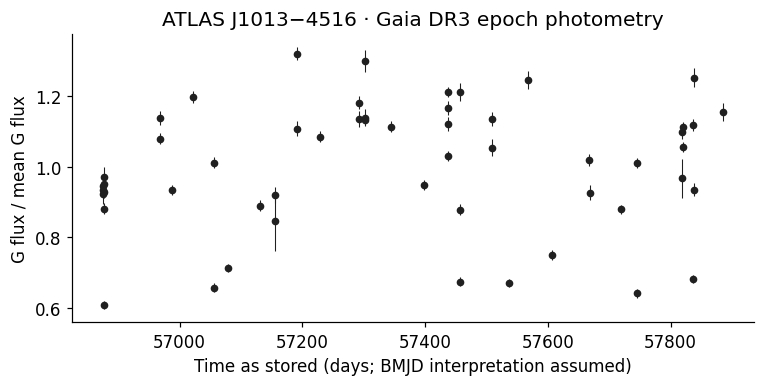

In [2]:
raw = np.loadtxt(DATA/'gaia.dat')
gaia = pd.DataFrame(raw, columns=['time_as_stored_days','column_1_undocumented',
                    'flux','flux_error','column_4_undocumented','column_5_undocumented'])
assert len(gaia) == 54
assert np.isfinite(gaia[['time_as_stored_days','flux','flux_error']]).all().all()
assert (gaia.flux_error > 0).all()
gaia.to_csv(TABLE/'gaia_epoch_photometry.csv',index=False)
print(f'{len(gaia)} points; {np.ptp(gaia.time_as_stored_days):.2f}-day baseline')
display(gaia.head())
fig, ax = plt.subplots(figsize=(8,3.4))
mean_flux = gaia.flux.mean()
ax.errorbar(gaia.time_as_stored_days,gaia.flux/mean_flux,
            gaia.flux_error/mean_flux,fmt='o',ms=4,color=COLORS['Gaia'],elinewidth=.7)
ax.set(xlabel='Time as stored (days; BMJD interpretation assumed)',
       ylabel='G flux / mean G flux',title='ATLAS J1013−4516 · Gaia DR3 epoch photometry')
save_figure(fig,'j1013_gaia_epochs')
plt.show()


## 2. ATLAS photometry and the original cleaning recipe

The original `data/atlas/reduced.txt` is bundled unchanged. To reproduce the source fold we apply
`chi/N < 10`, `mag5sig > 17`, shift the c-band median to the o-band median, then apply a pooled
±3-IQR flux cut. This intentionally follows the recovered recipe, rather than silently replacing it
with a new cleaning scheme. ATLAS fluxes are difference fluxes.

Ground-based MJD UTC is converted to BMJD TDB at the **Palomar location used by the original code**.
Coordinates come from the bundled Gaia JSON. Palomar's geocentric coordinates are recorded numerically
below, avoiding an online site-registry lookup. This reproduces that site's use for all input rows;
it does not constitute a new per-observatory timestamp audit. These inputs and cuts represent the
backed-up source notebook, not an independently reconstructed publication data release.


In [3]:
cols = ['MJD','m','dm','uJy','duJy','F','err','chiN','RA','Dec','x','y',
        'maj','min','phi','apfit','mag5sig','Sky','Obs']
atlas_raw = pd.read_csv(DATA/'atlas_reduced_original.txt',sep=r'\s+',comment='#',
                        names=cols,dtype={'F':str,'Obs':str})
atlas = atlas_raw.loc[(atlas_raw.chiN < 10) & (atlas_raw.mag5sig > 17)].copy()
n_quality = len(atlas)
delta_median = np.median(atlas.loc[atlas.F=='o','uJy']) - np.median(atlas.loc[atlas.F=='c','uJy'])
atlas.loc[atlas.F=='c','uJy'] += delta_median
iqr = np.diff(np.percentile(atlas.uJy,[25,75]))[0]
med = np.median(atlas.uJy)
atlas = atlas.loc[(atlas.uJy > med-3*iqr) & (atlas.uJy < med+3*iqr)].copy()
assert np.isfinite(atlas[['MJD','uJy','duJy']]).all().all() and (atlas.duJy > 0).all()
catalog = json.loads((DATA/'gaia_dr3.json').read_text())
coord = SkyCoord(catalog['coordinates']['ra_icrs_deg']*u.deg,
                 catalog['coordinates']['dec_icrs_deg']*u.deg)
palomar = EarthLocation.from_geocentric(-2410346.78217658*u.m,
                                       -4758666.82504051*u.m,3487942.97502457*u.m)
t = Time(atlas.MJD.to_numpy(),format='mjd',scale='utc')
atlas['bmjd_tdb'] = (t.tdb + t.tdb.light_travel_time(coord,kind='barycentric',location=palomar)).mjd
atlas.to_csv(TABLE/'atlas_cleaned_photometry.csv',index=False)
print(f'ATLAS: {len(atlas_raw)} input → {n_quality} quality-selected → {len(atlas)} IQR-selected')
display(atlas.groupby('F').agg(n=('uJy','size'),first_mjd=('MJD','min'),last_mjd=('MJD','max')))


ATLAS: 2128 input → 2007 quality-selected → 1946 IQR-selected


,n,first_mjd,last_mjd
F,,,
c,449,57453.407532,60648.321291
g,8,58195.330590,58195.424552
o,1489,57404.516962,60654.049231


## 3. Fold the Gaia and ATLAS light curves

We retain the source notebook's quadratic phase convention, inverse-variance binning, 50 bins,
and three displayed cycles. **The three cycles repeat the same measurements.** Gaia is normalized
by its mean flux. Each ATLAS band's folded flux is affinely rescaled to Gaia's folded interquartile
range, as in the original figure. This shows coherent morphology; the overlay is not an absolute
flux or independently calibrated color/amplitude comparison. Folding on a measured ephemeris is
not an independent Gaia period search or period-derivative fit.


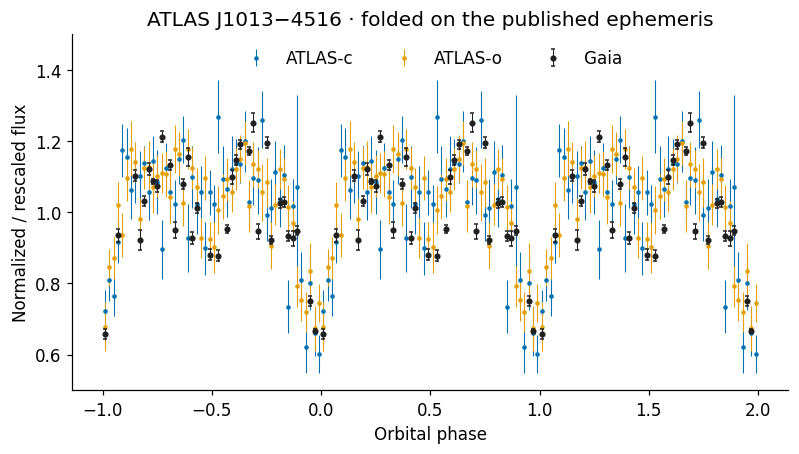

In [4]:
def phase_fold(time, period_days, pdot, t0):
    dt = np.asarray(time)-t0
    return ((dt - .5*pdot/period_days*dt**2) % period_days)/period_days

def binned_fold(time, flux, error):
    phase = phase_fold(time,P_PUBLISHED_S/86400,PDOT_PUBLISHED,T0_PUBLISHED)
    edges = np.linspace(0,1,N_PHASE_BINS+1)
    result = []
    for lo,hi in zip(edges[:-1],edges[1:]):
        m = (phase >= lo) & (phase < hi)
        if m.any():
            w = 1/np.asarray(error)[m]**2
            result.append([(lo+hi)/2,np.sum(np.asarray(flux)[m]*w)/w.sum(),np.sqrt(1/w.sum())])
        else:
            result.append([(lo+hi)/2,np.nan,np.nan])
    return np.asarray(result)

def repeated_cycles(binned):
    return np.vstack([binned+[-1,0,0],binned,binned+[1,0,0]])

g = binned_fold(gaia.time_as_stored_days,gaia.flux/mean_flux,gaia.flux_error/mean_flux)
# Quantiles of the repeated arrays reproduce the original notebook exactly.
qg = np.nanpercentile(repeated_cycles(g)[:,1],[25,75])
folds = {'Gaia':g}
transforms = []
for band in ('c','o'):
    d = atlas.loc[atlas.F==band]
    y,dy = d.uJy.to_numpy(),d.duJy.to_numpy()
    if band == 'o':
        dy = dy/y.mean(); y = y/y.mean()
    binned = binned_fold(d.bmjd_tdb,y,dy)
    q = np.percentile(repeated_cycles(binned)[:,1],[25,75])
    scale = np.diff(qg)[0]/np.diff(q)[0]
    offset = qg[0]-scale*q[0]
    binned[:,1] = scale*binned[:,1]+offset
    binned[:,2] *= scale
    folds[f'ATLAS-{band}'] = binned
    transforms.append(dict(band=band,scale=scale,offset=offset))
pd.DataFrame(transforms).to_csv(TABLE/'atlas_display_transforms.csv',index=False)
all_folds = pd.concat([pd.DataFrame(a,columns=['phase','display_flux','display_flux_error']).assign(survey=label)
                       for label,a in folds.items()],ignore_index=True)
all_folds.to_csv(TABLE/'gaia_atlas_folded_50bins.csv',index=False)

fig, ax = plt.subplots(figsize=(8.4,4.2))
for label in ('ATLAS-c','ATLAS-o','Gaia'):
    b = repeated_cycles(folds[label])
    ax.errorbar(b[:,0],b[:,1],b[:,2],fmt='o' if label=='Gaia' else '.',
                ms=3 if label=='Gaia' else 4,elinewidth=.7,capsize=1 if label=='Gaia' else 0,
                color=COLORS[label],label=label,zorder=3 if label=='Gaia' else 2)
ax.set(xlabel='Orbital phase',ylabel='Normalized / rescaled flux',ylim=(.5,1.5),
       title='ATLAS J1013−4516 · folded on the published ephemeris')
ax.legend(ncol=3,loc='upper center',frameon=False)
save_figure(fig,'j1013_gaia_atlas_fold')
plt.show()


## 4. Timing epochs: Gaia plus other observations

`data/timing_epochs.csv` preserves all 15 rows of the backed-up `timing1013.csv`, with explicit
column names, source-row numbers, and instrument labels inferred from the source O–C figure
annotations and observing-era grouping. `data/other_timing_epochs.csv` contains the 12 non-Gaia rows.
The original numeric table is included unchanged and has no instrument or time-scale header.

Use **sigma_s**, column 2 of the original table, for the timing uncertainty. The day-unit error
column was rounded in the source table and can differ by up to 0.005 s after conversion. Its last column is
numerically **1/sigma_s**, despite the source notebook's markdown describing it as an O–C error.
The stored cycle column is fractional; integer cycles are reconstructed below.

The three Gaia epochs are seasonal waveform timings, not single Gaia-observed eclipses. The final
photometry-to-three-timing-points procedure has not been recovered; this notebook reads those
timings rather than claiming to remeasure them. The two older `gaia1.dat`/`gaia2.dat` diagnostic
subsets do not document the final three-epoch procedure.


In [5]:
epochs = pd.read_csv(DATA/'timing_epochs.csv')
source = np.loadtxt(DATA/'timing1013_original.txt')
assert len(epochs)==15 and (epochs.instrument=='Gaia').sum()==3
np.testing.assert_allclose(epochs.sigma_s,epochs.sigma_days*86400,atol=0.005)
np.testing.assert_allclose(epochs.inverse_sigma_as_stored,1/epochs.sigma_s,rtol=1e-12)
T_REF = source[0,0]
P_REF_D = source[0,4]
P_REF_S = P_REF_D*86400
epochs['cycle_integer'] = np.rint(epochs.dt_days/P_REF_D).astype('int64')
recomputed_oc = (epochs.dt_days-epochs.cycle_integer*P_REF_D)*86400
np.testing.assert_allclose(recomputed_oc,epochs.oc_s,atol=1e-5)
epochs['year_for_display'] = Time(epochs.time_as_stored_days.to_numpy(),format='mjd',scale='tdb').decimalyear
print(f'Bundled table linear reference: T_ref = {T_REF:.10f}, P_ref = {P_REF_S:.12f} s')
display(epochs[['source_row','instrument','time_as_stored_days','cycle_integer','oc_s','sigma_s']]
        .sort_values('time_as_stored_days').reset_index(drop=True))


Bundled table linear reference: T_ref = 60033.2044883359, P_ref = 513.593300316553 s


,source_row,instrument,time_as_stored_days,cycle_integer,oc_s,sigma_s
0,8,Gaia,57000.238460,-510225,-123.202598,7.232343
1,9,Gaia,57400.235381,-442935,-82.365044,6.821396
2,10,Gaia,57750.245752,-384054,-73.441703,6.439020
3,11,ATLAS,58300.325977,-291516,-38.877951,8.531964
4,12,ATLAS,59100.010048,-156988,-14.646860,5.193422
5,13,ATLAS,59657.217320,-63251,-1.495497,3.861625
6,1,ULTRACAM,60033.204488,0,0.000000,0.434442
7,2,ULTRACAM,60034.262585,178,-0.050503,0.691042
8,3,ULTRACAM,60347.382093,52853,-1.626978,1.264423
9,4,ULTRACAM,60348.214297,52993,-2.252206,1.650222


## 5. O–C: refit the bundled table, with the version clearly labeled

The original notebook fits \(a_0+a_1\Delta t+\tfrac12(\dot P/P_{ref})\Delta t^2\)
to the stored O–C values with the supplied timing errors. We solve the same weighted linear
problem using a rescaled time variable for numerical stability, with absolute supplied errors
(no reduced-chi-square error rescaling). The polynomial coefficients absorb changes of zero
point and reference period. This is a joint-data result; Gaia alone is not being claimed to
measure Pdot. The error is the formal covariance of this fit and includes no new systematic model.


Bundled-table refit: Pdot = (-1.725 ± 0.056) × 10^-12 s/s
Published result:     Pdot = (-1.60 ± 0.07) × 10^-12 s/s
chi2 / dof = 6.25 / 12; no error rescaling applied


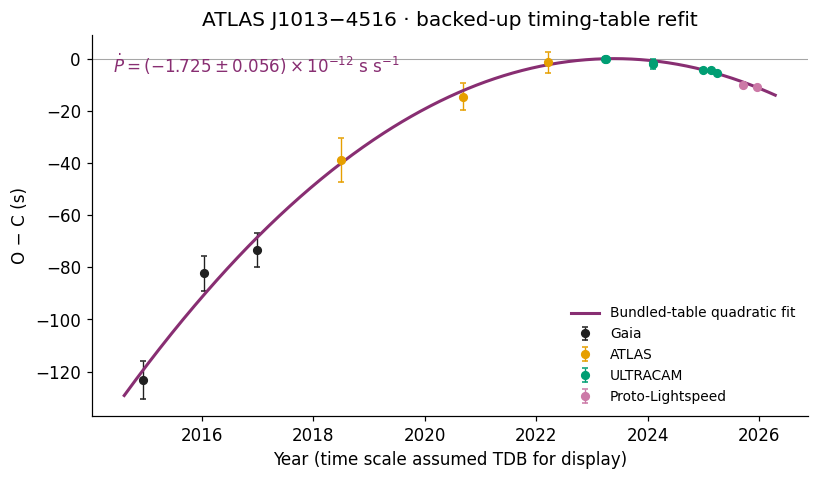

In [6]:
dt_s = epochs.dt_days.to_numpy()*86400
x = dt_s/1e8
A = np.column_stack([np.ones(len(x)),x,x*x])
sigma = epochs.sigma_s.to_numpy()
Aw = A/sigma[:,None]
beta = np.linalg.lstsq(Aw,epochs.oc_s.to_numpy()/sigma,rcond=None)[0]
cov = np.linalg.inv(Aw.T@Aw)
pdot_fit = 2*P_REF_S*beta[2]/1e16
pdot_error = 2*P_REF_S*np.sqrt(cov[2,2])/1e16
np.testing.assert_allclose(pdot_fit,-1.7251209492269783e-12,rtol=1e-7)
np.testing.assert_allclose(pdot_error,5.5987209718658666e-14,rtol=1e-6)
residual = epochs.oc_s.to_numpy()-A@beta
chi2 = float(np.sum((residual/sigma)**2))
fit_summary = dict(pdot_s_per_s=float(pdot_fit),formal_sigma_s_per_s=float(pdot_error),
                   chi2=chi2,dof=len(epochs)-3,reference_period_s=float(P_REF_S),
                   reference_time_as_stored_days=float(T_REF),
                   published_pdot_s_per_s=PDOT_PUBLISHED,published_sigma_s_per_s=0.07e-12,
                   fit_version='Backed-up timing table refit; distinct from the published result')
(TABLE/'oc_fit_summary.json').write_text(json.dumps(fit_summary,indent=2))
print(f'Bundled-table refit: Pdot = ({pdot_fit/1e-12:.3f} ± {pdot_error/1e-12:.3f}) × 10^-12 s/s')
print('Published result:     Pdot = (-1.60 ± 0.07) × 10^-12 s/s')
print(f'chi2 / dof = {chi2:.2f} / {len(epochs)-3}; no error rescaling applied')

fig, ax = plt.subplots(figsize=(8.4,4.5))
for instrument in ('Gaia','ATLAS','ULTRACAM','Proto-Lightspeed'):
    d = epochs.loc[epochs.instrument==instrument]
    ax.errorbar(d.year_for_display,d.oc_s,d.sigma_s,fmt='o',ms=5,
                color=COLORS[instrument],capsize=2,elinewidth=.9,label=instrument)
grid = np.linspace(dt_s.min()-120*86400,dt_s.max()+120*86400,500)
Ag = np.column_stack([np.ones(len(grid)),grid/1e8,(grid/1e8)**2])
yr = Time(T_REF+grid/86400,format='mjd',scale='tdb').decimalyear
ax.plot(yr,Ag@beta,color='#882E72',lw=2,label='Bundled-table quadratic fit')
ax.axhline(0,color='.65',lw=.7,zorder=0)
ax.set(xlabel='Year (time scale assumed TDB for display)',ylabel='O − C (s)',
       title='ATLAS J1013−4516 · backed-up timing-table refit')
ax.text(.03,.90,rf'$\dot P = ({pdot_fit/1e-12:.3f}\pm{pdot_error/1e-12:.3f})\times10^{{-12}}$ s s$^{{-1}}$',
         transform=ax.transAxes,color='#882E72',fontsize=11)
ax.legend(loc='lower right',fontsize=9,frameon=False)
save_figure(fig,'j1013_oc_bundled_table_refit')
plt.show()

epochs['quadratic_model_oc_s'] = A@beta
epochs['quadratic_residual_s'] = residual
epochs.sort_values('time_as_stored_days').to_csv(TABLE/'timing_epochs_with_fit.csv',index=False)


## 6. Remeasure the Gaia seasonal epochs from photometry

This is a **new, explicit estimator**, not a recovered version of the unpublished original timing
pipeline. It reads the individual flux measurements, not the three stored Gaia O–C values.
The stored values enter only afterward as a comparison and to choose the integer cycle at which
each seasonal result is reported; they do not enter the flux likelihood.

We transfer the saved high-speed g-band LCURVE waveform to Gaia, fitting a time shift, a positive
amplitude, and an offset per season. The template's conjunction phase comes from its saved model
file. Its geometry is held fixed. The season boundaries are explicit: times below 57200, 57200–57600,
and above 57600 days, giving 20/19/15 measurements. These boundaries are a transparent new choice;
the precise original three-season selection has not been recovered.

**Avoiding a circular Pdot constraint:** within-season phase evolution is taken from a quadratic
ephemeris fitted to the **12 non-Gaia timings only**. Each Gaia seasonal shift is then free. The
published Pdot is not imposed on the Gaia timing fit. This improves on folding a whole season
at one constant period, which would smear the slowly evolving waveform. Uncertainty in that
external phase evolution is not marginalized; these are conditional seasonal measurements.

The headerless Gaia times are still used **as stored**. Their TCB/TDB ingestion remains unverified;
an unknown common time offset would propagate to the measured epochs. There are two measurements
only about 4 ms apart; without transit IDs their independence cannot be checked. No deduplication
is silently applied.


In [7]:
from scipy.interpolate import CubicSpline
from scipy.optimize import minimize_scalar, brentq

# Fit only the non-Gaia timing rows for phase evolution within each season.
external = pd.read_csv(DATA/'other_timing_epochs.csv')
E_ext = np.rint(external.dt_days.to_numpy()*86400/P_REF_S).astype('int64')
X_ext = np.column_stack([np.ones(len(E_ext)),E_ext/1e5,(E_ext/1e5)**2])
w_ext = 1/external.sigma_s.to_numpy()
b_ext = np.linalg.lstsq(X_ext*w_ext[:,None],external.oc_s.to_numpy()*w_ext,rcond=None)[0]
EXT_A = b_ext[0]
EXT_P = P_REF_S+b_ext[1]/1e5
EXT_C = b_ext[2]/1e10

def external_epoch(cycle):
    return T_REF+(EXT_A+EXT_P*np.asarray(cycle)+EXT_C*np.asarray(cycle)**2)/86400

def external_cycles(time):
    dt = (np.asarray(time)-T_REF)*86400-EXT_A
    # Stable inverse of dt = P E + C E^2.
    return 2*dt/(EXT_P+np.sqrt(EXT_P**2+4*EXT_C*dt))

model = np.loadtxt(DATA/'ultracam_g_lcurve_template.dat')
template_meta = json.loads((DATA/'template_metadata.json').read_text())
xp = model[:,0]-template_meta['phase_conjunction']
yp = model[:,2]/np.mean(model[:,2])
assert np.isclose(xp[0],0) and np.isclose(xp[-1],1)
assert np.isclose(yp[0],yp[-1],atol=1e-8)
yp[-1] = yp[0]  # exactly close the periodic spline (roundoff only)
timing_template = CubicSpline(xp,yp,bc_type='periodic')
print(f'Non-Gaia-only phase evolution: Pdot = {2*EXT_C/EXT_P/1e-12:.3f} × 10^-12 s/s')
print('The next fit uses individual Gaia fluxes, independent free seasonal shifts, and no stored Gaia O-C constraints.')


Non-Gaia-only phase evolution: Pdot = -1.728 × 10^-12 s/s
The next fit uses individual Gaia fluxes, independent free seasonal shifts, and no stored Gaia O-C constraints.


### Profile likelihood, exposure response, and uncertainty

The nominal response averages the template over an assumed **44-second uniform boxcar**. The
effective Gaia response is not documented in the recovered file, so we also fit with zero extra
averaging. Neither this choice nor the file's 8.64-second placeholder column is treated as a
verified response function. At each trial shift, amplitude and offset are solved analytically;
the scan covers one full orbital cycle and is refined around the best minimum.

Errors are the contiguous profile interval around that minimum at

\[
\Delta\chi^2=\max[1,\chi^2_{\min}/(N-3)].
\]

This residual-based scaling inflates the errors when the fixed template fits poorly. It does not
calibrate template-transfer errors, correlated measurements, phase evolution, or the time scale.
**Poor fits remain poor fits after scaling**; the results are exploratory rather than a new
precision orbital-decay measurement. A second diagnostic permits an extra first-harmonic sine
and cosine baseline; a half-cycle switch then exposes eclipse-label sensitivity.


In [8]:
def fit_gaia_season(t,y,error,exposure_s=44.0,harmonic=False):
    t,y,error = map(np.asarray,(t,y,error))
    base_phase = external_cycles(t) % 1
    nuisance = np.column_stack([np.ones(len(t)),np.cos(2*np.pi*base_phase),np.sin(2*np.pi*base_phase)]) if harmonic else np.ones((len(t),1))
    # Weighted projection removes nuisance coefficients at every trial shift.
    Q,_ = np.linalg.qr(nuisance/error[:,None],mode='reduced')
    yw = y/error
    yr = yw-Q@(Q.T@yw)
    offsets = ((np.arange(21)+.5)/21-.5)*exposure_s

    def template_at(shifts):
        shifts = np.atleast_1d(shifts)
        tt = t[None,:,None]+(offsets[None,None,:]-shifts[:,None,None])/86400
        return timing_template(external_cycles(tt)%1).mean(axis=2)

    def profile(shifts):
        m = template_at(shifts)/error[None,:]
        mr = m-(m@Q)@Q.T
        denom = np.sum(mr*mr,axis=1)
        amplitude = (mr@yr)/denom
        chi = yr@yr-(mr@yr)**2/denom
        return np.where(amplitude>0,np.maximum(chi,0),1e30)

    grid = np.linspace(-P_REF_S/2,P_REF_S/2,2049)
    chi = profile(grid)
    i = int(np.argmin(chi))
    opt = minimize_scalar(lambda sh:float(profile([sh])[0]),
            bounds=(grid[max(0,i-1)],grid[min(len(grid)-1,i+1)]),method='bounded',options={'xatol':1e-7})
    shift,cmin = float(opt.x),float(opt.fun)
    n_parameters = nuisance.shape[1]+2  # nuisance + template amplitude + shift
    dof = len(t)-n_parameters
    error_scale = max(1,cmin/dof)
    threshold = cmin+error_scale

    def crossing(direction):
        trial = shift+direction*np.linspace(0,P_REF_S/2,2049)
        v = profile(trial)-threshold
        hits = np.flatnonzero(v>0)
        if not len(hits): return np.nan
        j = int(hits[0])
        return brentq(lambda sh:float(profile([sh])[0]-threshold),*sorted([trial[j-1],trial[j]]),xtol=1e-7)
    lower,upper = crossing(-1),crossing(1)
    X = np.column_stack([template_at([shift])[0],nuisance])
    coeff = np.linalg.lstsq(X/error[:,None],yw,rcond=None)[0]
    circular_distance = np.abs((grid-shift+P_REF_S/2)%P_REF_S-P_REF_S/2)
    opposite = circular_distance > P_REF_S/4
    return dict(shift_s=shift,error_minus_s=shift-lower,error_plus_s=upper-shift,
                chi2=cmin,dof=dof,chi2nu=cmin/dof,error_scale=error_scale,
                opposite_half_delta_chi2=(float(chi[opposite].min()-cmin) if chi[opposite].min()<1e29 else np.nan),
                grid=grid,chi2_profile=chi,coeff=coeff,profile=profile,
                template_at=template_at,model=X@coeff)

# Sign/units sanity check at the actual cadence: an exact shifted template must be recovered.
test_t = gaia.time_as_stored_days.to_numpy()[:20]
test_offsets = ((np.arange(21)+.5)/21-.5)*44
injected_shift_s = 7.25
test_y = .15+1.2*timing_template(external_cycles(test_t[:,None]+(test_offsets-injected_shift_s)/86400)%1).mean(axis=1)
injected = fit_gaia_season(test_t,test_y,np.full(len(test_t),.02))
assert abs(injected['shift_s']-injected_shift_s)<0.005
print(f'Synthetic shift recovery: injected {injected_shift_s:.3f} s, recovered {injected["shift_s"]:.3f} s')


Synthetic shift recovery: injected 7.250 s, recovered 7.250 s


,season,n,time_as_stored_days,oc_s,error_minus_s,error_plus_s,chi2nu,difference_from_legacy_s
0,1,20,57000.238671,-104.963004,11.805087,10.804830,34.269343,18.239594
1,2,19,57400.235448,-76.579990,8.663262,7.658853,15.685821,5.785054
2,3,15,57750.245701,-77.876550,8.162883,8.013701,19.720447,-4.434847


,season,variant,shift_s,delta_from_nominal_s,chi2nu,half_cycle_switch
0,1,44s fixed template,14.972896,0.000000,34.269343,False
1,1,0s extra smearing,18.282345,3.309449,33.953662,False
2,1,44s + first-harmonic baseline,-244.541634,254.078770,29.298732,True
3,2,44s fixed template,14.320662,0.000000,15.685821,False
4,2,0s extra smearing,14.230994,-0.089667,15.812283,False
5,2,44s + first-harmonic baseline,-242.295768,-256.616430,12.189320,True
6,3,44s fixed template,-9.085756,0.000000,19.720447,False
7,3,0s extra smearing,-10.002255,-0.916499,18.856396,False
8,3,44s + first-harmonic baseline,-6.924068,2.161688,20.147238,False


Residual-scaled profile errors are conditional. Large chi2nu and half-cycle switches flag template sensitivity.


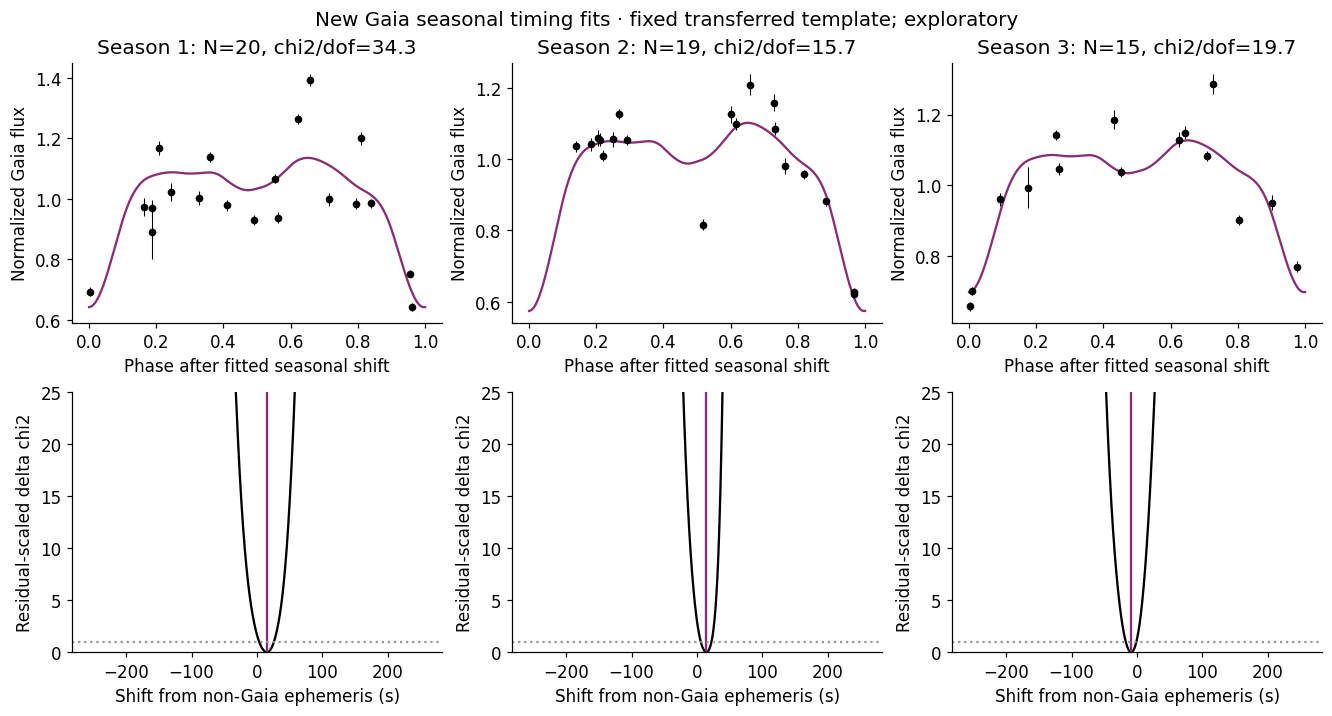

In [9]:
SEASON_EDGES = [-np.inf,57200,57600,np.inf]
legacy_gaia = epochs.loc[epochs.instrument=='Gaia'].reset_index(drop=True)
measured_rows, sensitivity_rows, season_fits = [],[],[]
for j,(lo,hi) in enumerate(zip(SEASON_EDGES[:-1],SEASON_EDGES[1:])):
    d = gaia.loc[(gaia.time_as_stored_days>=lo)&(gaia.time_as_stored_days<hi)]
    t = d.time_as_stored_days.to_numpy()
    mean = d.flux.mean(); y = d.flux.to_numpy()/mean; error = d.flux_error.to_numpy()/mean
    result = fit_gaia_season(t,y,error)
    unsmeared = fit_gaia_season(t,y,error,exposure_s=0)
    flexible = fit_gaia_season(t,y,error,harmonic=True)
    # Select the same reported integer cycle as the stored timing, for comparison only.
    report_cycle = int(legacy_gaia.iloc[j].cycle_integer)
    measured_time = float(external_epoch(report_cycle)+result['shift_s']/86400)
    measured_oc = (measured_time-(T_REF+report_cycle*P_REF_D))*86400
    row = dict(season=j+1,n=len(t),first_time_as_stored_days=t.min(),last_time_as_stored_days=t.max(),
               cycle_integer=report_cycle,time_as_stored_days=measured_time,oc_s=measured_oc,
               sigma_s=max(result['error_minus_s'],result['error_plus_s']),
               error_minus_s=result['error_minus_s'],error_plus_s=result['error_plus_s'],
               shift_from_non_gaia_ephemeris_s=result['shift_s'],chi2nu=result['chi2nu'],
               legacy_oc_s=float(legacy_gaia.iloc[j].oc_s),
               difference_from_legacy_s=measured_oc-float(legacy_gaia.iloc[j].oc_s),
               opposite_half_delta_chi2=result['opposite_half_delta_chi2'],
               status='Exploratory fixed-template remeasurement; time scale assumed as stored')
    measured_rows.append(row)
    for label,fit in [('44s fixed template',result),('0s extra smearing',unsmeared),('44s + first-harmonic baseline',flexible)]:
        delta = (fit['shift_s']-result['shift_s']+P_REF_S/2)%P_REF_S-P_REF_S/2
        sensitivity_rows.append(dict(season=j+1,variant=label,shift_s=fit['shift_s'],
                 delta_from_nominal_s=delta,chi2nu=fit['chi2nu'],half_cycle_switch=abs(delta)>P_REF_S/4))
    season_fits.append(dict(data=d,t=t,y=y,error=error,result=result))

measured_gaia = pd.DataFrame(measured_rows)
timing_sensitivity = pd.DataFrame(sensitivity_rows)
measured_gaia.to_csv(TABLE/'gaia_measured_timing_epochs.csv',index=False)
timing_sensitivity.to_csv(TABLE/'gaia_timing_sensitivity.csv',index=False)
display(measured_gaia[['season','n','time_as_stored_days','oc_s','error_minus_s','error_plus_s','chi2nu','difference_from_legacy_s']])
display(timing_sensitivity)
print('Residual-scaled profile errors are conditional. Large chi2nu and half-cycle switches flag template sensitivity.')

fig,axes = plt.subplots(2,3,figsize=(12,6.4),layout='constrained')
for j,group in enumerate(season_fits):
    t,y,error,result = group['t'],group['y'],group['error'],group['result']
    ph = external_cycles(t-result['shift_s']/86400)%1
    ax = axes[0,j];ax.errorbar(ph,y,error,fmt='o',ms=4,color='k',elinewidth=.7)
    pp = np.linspace(0,1,600)
    smooth = timing_template((pp[:,None]+(((np.arange(21)+.5)/21-.5)*44/EXT_P))%1).mean(axis=1)
    ax.plot(pp,result['coeff'][0]*smooth+result['coeff'][1],color='#882E72')
    ax.set(xlabel='Phase after fitted seasonal shift',ylabel='Normalized Gaia flux',title=f'Season {j+1}: N={len(t)}, chi2/dof={result["chi2nu"]:.1f}')
    ax = axes[1,j]
    ax.plot(result['grid'],(result['chi2_profile']-result['chi2'])/result['error_scale'],color='k')
    ax.axvline(result['shift_s'],color='#882E72');ax.axhline(1,color='.6',ls=':')
    ax.set(xlabel='Shift from non-Gaia ephemeris (s)',ylabel='Residual-scaled delta chi2',ylim=(0,25))
fig.suptitle('New Gaia seasonal timing fits · fixed transferred template; exploratory',fontsize=13)
save_figure(fig,'j1013_gaia_timing_profiles')
plt.show()


## 7. O–C using the newly measured Gaia epochs

This plot uses **only the 12 non-Gaia timing rows plus the three new flux-based measurements**.
The original Gaia epochs are shown as open comparison markers and do not enter the fit.
For this illustrative weighted fit we use the larger of the two asymmetric profile errors.
Template-transfer/alias sensitivity and the unresolved input time scale are not folded into a
calibrated joint uncertainty. This is **not a replacement for the published ephemeris**.


Illustrative remeasured-Gaia fit: Pdot = (-1.651 ± 0.073) × 10^-12 s/s (conditional formal error)


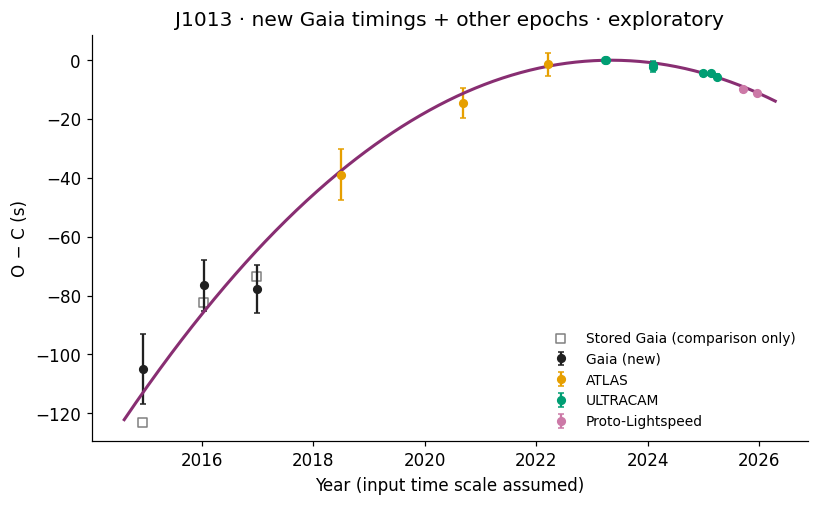

In [10]:
remeasured = external[['time_as_stored_days','sigma_s','instrument']].copy()
fresh = measured_gaia[['time_as_stored_days','sigma_s']].copy();fresh['instrument']='Gaia'
remeasured = pd.concat([remeasured,fresh],ignore_index=True)
remeasured['dt_days'] = remeasured.time_as_stored_days-T_REF
remeasured['cycle_integer'] = np.rint(remeasured.dt_days/P_REF_D).astype('int64')
remeasured['oc_s'] = (remeasured.dt_days-remeasured.cycle_integer*P_REF_D)*86400
xx = remeasured.dt_days.to_numpy()*86400/1e8
AA = np.column_stack([np.ones(len(xx)),xx,xx*xx])
ss = remeasured.sigma_s.to_numpy()
bb = np.linalg.lstsq(AA/ss[:,None],remeasured.oc_s.to_numpy()/ss,rcond=None)[0]
CC = np.linalg.inv((AA/ss[:,None]).T@(AA/ss[:,None]))
new_pdot = 2*P_REF_S*bb[2]/1e16
new_pdot_error = 2*P_REF_S*np.sqrt(CC[2,2])/1e16
remeasured['year_for_display'] = Time(remeasured.time_as_stored_days.to_numpy(),format='mjd',scale='tdb').decimalyear
remeasured.sort_values('time_as_stored_days').to_csv(TABLE/'timing_epochs_remeasured_gaia.csv',index=False)
summary = dict(pdot_s_per_s=float(new_pdot),conditional_formal_sigma_s_per_s=float(new_pdot_error),
               status='Illustrative joint fit with new conditional Gaia timings; not the published result',
               phase_reference='Non-Gaia quadratic ephemeris',gaia_response_assumption_s=44,
               unresolved_systematics=['Gaia stored time scale','g-to-G template transfer','half-cycle labeling',
                                       'correlated measurements','external intra-season ephemeris uncertainty'])
(TABLE/'oc_remeasured_gaia_summary.json').write_text(json.dumps(summary,indent=2))
print(f'Illustrative remeasured-Gaia fit: Pdot = ({new_pdot/1e-12:.3f} ± {new_pdot_error/1e-12:.3f}) × 10^-12 s/s (conditional formal error)')
fig,ax = plt.subplots(figsize=(8.4,4.8))
for instrument in ('Gaia','ATLAS','ULTRACAM','Proto-Lightspeed'):
    d = remeasured.loc[remeasured.instrument==instrument]
    ax.errorbar(d.year_for_display,d.oc_s,d.sigma_s,fmt='o',color=COLORS[instrument],ms=5,capsize=2,label=instrument+' (new)' if instrument=='Gaia' else instrument)
ax.scatter(legacy_gaia.year_for_display,legacy_gaia.oc_s,marker='s',s=35,facecolors='none',edgecolors='.5',label='Stored Gaia (comparison only)')
ax.plot(yr,Ag@bb,color='#882E72',lw=2)
ax.set(xlabel='Year (input time scale assumed)',ylabel='O − C (s)',title='J1013 · new Gaia timings + other epochs · exploratory')
ax.legend(loc='lower right',fontsize=9,frameon=False)
save_figure(fig,'j1013_oc_remeasured_gaia')
plt.show()


## Provenance and generated products

Original inputs are author-provided analysis products for ATLAS J1013−4516.
`data/source_manifest.json` records their original analysis-relative filenames and SHA256 checksums.

The implementation follows `scripts/gaia/plot_gaia_atlas.ipynb`, `utils/photometry.py`, and
`scripts/pdot/plot_oc.ipynb` in that project. The standalone notebook removes git-root lookup,
online site lookup, and the stray final syntax-error cell; it uses a portable font and an equivalent
stable weighted-linear O–C solver. Time-axis display uses TDB consistently rather than the source
O–C notebook's UTC display declaration. No timing datum has been altered.

Run All writes PDF/PNG figures to `figures/` and numeric products to `tables/`:
Gaia epoch photometry; cleaned ATLAS photometry; 50-bin Gaia/ATLAS folds; affine display transforms;
labeled timing epochs with residuals; and a version-labeled O–C fit summary.

For a talk quoting the published Pdot, use the published Figure 7 (or first resolve the source-table
version discrepancy). The O–C plot produced here explicitly represents the recoverable backed-up table.

New timing products: `gaia_measured_timing_epochs.csv`, `gaia_timing_sensitivity.csv`, `timing_epochs_remeasured_gaia.csv`, and `oc_remeasured_gaia_summary.json`. The additional template is the saved `results/lcurve/good/good_model_g.dat`, with conjunction phase from `good.mod`. SciPy is required.
